# Part 5 — Development and Model Selection

**BFT65B — Big Data Analytics in Finance | Student ID: 11230945**

Compare predefined models using purged chronological development folds. Set an event-level economic alarm threshold from out-of-fold predictions, demonstrate Spark MLlib and seal the final development estimators. No historical test is scored in this notebook.

## 1. Repository and runtime
Use a fresh CPU runtime, Java 17 or later, and the pinned dependencies. Use the same Python and dependency versions for both Part 5 notebooks.

In [1]:
from pathlib import Path
import os, sys, subprocess, json, shutil
REPO_URL = "https://github.com/NguyenDuong0508/11230945.git"
REPO = Path("/content/11230945")
if not REPO.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
else:
    assert subprocess.check_output(["git", "remote", "get-url", "origin"], cwd=REPO, text=True).strip() == REPO_URL
    subprocess.run(["git", "pull", "--ff-only"], cwd=REPO, check=True)
print("Git revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip())
java = shutil.which("java")
if java is None:
    raise RuntimeError("Java 17 or later is required")
os.environ["JAVA_HOME"] = str(Path(java).resolve().parents[1])
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
print(subprocess.run([java,"-version"],check=True,capture_output=True,text=True).stderr)
subprocess.run([sys.executable,"-m","pip","install","-r",str(REPO/"requirements.txt")],check=True)
sys.path.insert(0,str(REPO/'src'))
def command(action):
    proc = subprocess.Popen([sys.executable,str(REPO/'run_part5.py'),action,'--workspace',str(WORKSPACE)],cwd=REPO,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,text=True,bufsize=1)
    for line in proc.stdout:
        print(line,end='',flush=True)
    if proc.wait()!=0:
        raise RuntimeError(f'Part 5 {action} failed; inspect diagnostics')

Git revision: e74142601962bf6646798e5564eb9d4ab56c271a
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)



## 2. Mandatory offline validation
Run the complete test suite, including real Parquet and Spark integration. A failed or skipped test stops the pipeline.

In [2]:
import xml.etree.ElementTree as ET
TESTS_PASSED = False
result_path = Path('/content/part5_tests.xml')
result_path.unlink(missing_ok=True)
result = subprocess.run([sys.executable,'-m','pytest','-q','-ra','--tb=short','--show-capture=no',f'--junitxml={result_path}','tests'],cwd=REPO,env=dict(os.environ,PYTEST_DISABLE_PLUGIN_AUTOLOAD='1',SPARK_LOCAL_IP='127.0.0.1',PYSPARK_PYTHON=sys.executable,MPLBACKEND='Agg'),capture_output=True,text=True)
print(result.stdout)
if result.stderr: print(result.stderr)
if not result_path.is_file(): raise RuntimeError('Missing pytest report')
cases=list(ET.parse(result_path).getroot().iter('testcase'))
problems=[(case,node) for case in cases for node in case if node.tag in ('failure','error','skipped')]
for case,node in problems:
    print(case.get('classname'),case.get('name'),node.tag,node.get('message'),node.text or '')
if result.returncode or not cases or problems: raise RuntimeError('Offline validation failed; inspect diagnostics')
TESTS_PASSED=True
print(f'Mandatory offline validation: PASS ({len(cases)} tests, zero skips)')

........................................................................ [ 54%]
............................................................             [100%]
----------------- generated xml file: /content/part5_tests.xml -----------------
132 passed in 314.36s (0:05:14)

Mandatory offline validation: PASS (132 tests, zero skips)


## 3. Verified upstream identities
Check the sealed Gold and Silver inventories and Bronze manifest identity. Development does not decode the historical test partitions.

In [3]:
from google.colab import drive
drive.mount('/content/drive')
WORKSPACE=Path('/content/drive/MyDrive/11230945')
assert TESTS_PASSED
from fdic_ews.modelling.pipeline import upstream, evidence_path, verify_development, verify_oof
from fdic_ews.contracts import sha256
GOLD, gm, SILVER, IDENTITY = upstream(WORKSPACE)
EVIDENCE=evidence_path(WORKSPACE,IDENTITY)
ATTEMPT=EVIDENCE.parent/'test_attempt.json'
print('Verified upstream identities:',json.dumps(IDENTITY,indent=2))
print('Gold decision quarters:',gm['summary']['decision_quarters'])
print('Gold predictors:',gm['summary']['feature_count'])
print('Represented test-calendar failures:',gm['summary']['test_distinct_failure_certs_in_calendar_period'])
print('Evidence directory:',EVIDENCE)

Mounted at /content/drive
Verified upstream identities: {
  "gold": "de2abf748e29025760f50cc6c3c57d899a4402fe079756e17f9a6d93f21b5780",
  "silver": "b6d91c7d0095b81e6200a0ae0940a103968c452046b168e446cd02089d323af0",
  "bronze": "e376152baac058e4dd4fff4582e9afa3c58820fff2f278115a82bff7fd4b3f6e"
}
Gold decision quarters: 166
Gold predictors: 29
Represented test-calendar failures: 505
Evidence directory: /content/drive/MyDrive/11230945/modelling/de2abf748e29025760f50cc6c3c57d899a4402fe079756e17f9a6d93f21b5780


## 4. Fixed chronological design and candidate specifications
The late validation block is sparse in failures. Four validation blocks cover distinct historical regimes. Every fold has a four-quarter gap between its training end and validation start; model fitting and threshold estimation use development only.

In [4]:
import pandas as pd
import numpy as np
from IPython.display import display
from fdic_ews.modelling.design import FOLDS,SPECS,validate_design
validate_design()
display(pd.DataFrame([{'fold':f.name,'training_end':f.train_end,'validation_start':f.start,'validation_end':f.end} for f in FOLDS]))
display(pd.DataFrame([{'specification':name,'estimator':kind,'raw_predictors':len(features),'capital_zero_as_missing':mask} for name,(kind,features,mask) in SPECS.items()]))

,fold,training_end,validation_start,validation_end
0,F1,1987-12-31,1989-03-31,1992-12-31
1,F2,1992-12-31,1994-03-31,1997-12-31
2,F3,1997-12-31,1999-03-31,2000-12-31
3,F4,2000-12-31,2002-03-31,2006-12-31


,specification,estimator,raw_predictors,capital_zero_as_missing
0,prior,prior,29,False
1,logistic,logistic,29,False
2,hist_gradient,hist_gradient,29,False
3,lightgbm_full,lightgbm,29,False
4,lightgbm_core,lightgbm,21,False
5,lightgbm_no_peer,lightgbm,28,False
6,lightgbm_no_quality,lightgbm,22,False
7,lightgbm_zero_missing,lightgbm,29,True


## 5. Execute development and seal the choices
The initial run performs all 32 fold fits, development-only threshold optimization, the native Spark demonstration and two final development refits. An existing sealed run is inspected without refitting. An incomplete run must be diagnosed; do not overwrite a sealed run.

In [5]:
if (EVIDENCE/'development_manifest.json').is_file():
    print('Existing development seal: read-only verification.')
else:
    if ATTEMPT.exists(): raise RuntimeError('Historical test already attempted; development is closed')
    command('develop')
DM=verify_development(EVIDENCE,IDENTITY)
verify_oof(EVIDENCE,DM)
S=DM['summary']
SELECTED=S['selected_model']
print('Development state:',DM['state'])
print('Selection:',SELECTED)
print('Seal SHA-256:',sha256(EVIDENCE/'development_manifest.json'))
print('Historical test scored: no (this notebook)')

F1 prior: AP=0.016548
F1 logistic: AP=0.362873
F1 hist_gradient: AP=0.360990
F1 lightgbm_full: AP=0.405031
F1 lightgbm_core: AP=0.360144
F1 lightgbm_no_peer: AP=0.392576
F1 lightgbm_no_quality: AP=0.371453
F1 lightgbm_zero_missing: AP=0.390486
F2 prior: AP=0.000514
F2 logistic: AP=0.190948
F2 hist_gradient: AP=0.232941
F2 lightgbm_full: AP=0.231012
F2 lightgbm_core: AP=0.219137
F2 lightgbm_no_peer: AP=0.245790
F2 lightgbm_no_quality: AP=0.245155
F2 lightgbm_zero_missing: AP=0.210873
F3 prior: AP=0.000656
F3 logistic: AP=0.114362
F3 hist_gradient: AP=0.223666
F3 lightgbm_full: AP=0.210230
F3 lightgbm_core: AP=0.202992
F3 lightgbm_no_peer: AP=0.196996
F3 lightgbm_no_quality: AP=0.226945
F3 lightgbm_zero_missing: AP=0.199252
F4 prior: AP=0.000255
F4 logistic: AP=0.021935
F4 hist_gradient: AP=0.013041
F4 lightgbm_full: AP=0.018275
F4 lightgbm_core: AP=0.025254
F4 lightgbm_no_peer: AP=0.018860
F4 lightgbm_no_quality: AP=0.023560
F4 lightgbm_zero_missing: AP=0.023965
[0.001s][warning][os,con

## 6. Chronological validation results
Average precision is the primary selection measure. Report fold-specific prevalence, AP, ROC-AUC and Brier score. Equal-weight fold averages are used for selection; pooled OOF metrics are complementary because score scales can vary across folds.

Table 1. Chronological fold populations


,fold,train_end,validation_start,validation_end,train_rows,train_positive,validation_rows,validation_positive,validation_events
0,F1,1987-12-31,1989-03-31,1992-12-31,258180,2536,233498,3864,1090
1,F2,1992-12-31,1994-03-31,1997-12-31,555746,7458,180852,93,33
2,F3,1997-12-31,1999-03-31,2000-12-31,788194,7646,77743,51,17
3,F4,2000-12-31,2002-03-31,2006-12-31,906299,7718,176285,45,15


Table 2. Fold-level average precision


fold,F1,F2,F3,F4
model,,,,
hist_gradient,0.360990,0.232941,0.223666,0.013041
lightgbm_core,0.360144,0.219137,0.202992,0.025254
lightgbm_full,0.405031,0.231012,0.210230,0.018275
lightgbm_no_peer,0.392576,0.245790,0.196996,0.018860
lightgbm_no_quality,0.371453,0.245155,0.226945,0.023560
lightgbm_zero_missing,0.390486,0.210873,0.199252,0.023965
logistic,0.362873,0.190948,0.114362,0.021935
prior,0.016548,0.000514,0.000656,0.000255


Table 3. Model comparison


,model,mean_ap,mean_roc_auc,mean_brier,median_fit_seconds,early_folds_mean_ap,late_fold_ap,selected
0,lightgbm_no_quality,0.216778,0.912264,0.003579,18.693480,0.281185,0.023560,True
1,lightgbm_full,0.216137,0.917694,0.003471,21.360213,0.282091,0.018275,False
2,lightgbm_no_peer,0.213555,0.915902,0.003465,20.439389,0.278454,0.018860,False
3,hist_gradient,0.207659,0.910935,0.003597,27.763134,0.272532,0.013041,False
4,lightgbm_zero_missing,0.206144,0.920698,0.003438,22.027424,0.266870,0.023965,False
5,lightgbm_core,0.201882,0.919579,0.003607,16.573949,0.260758,0.025254,False
6,logistic,0.172530,0.883830,0.003789,22.914926,0.222728,0.021935,False
7,prior,0.004493,0.500000,0.004515,0.073300,0.005906,0.000255,False


Table 4. Pooled out-of-fold ranking diagnostics


,model,rows,positives,prevalence,ap,roc_auc,brier,log_loss,recall_top5pct_by_quarter
0,prior,668378,4053,0.006064,0.009286,0.554560,0.006057,0.038435,0.006662
1,logistic,668378,4053,0.006064,0.283796,0.847136,0.005058,0.026527,0.662966
2,hist_gradient,668378,4053,0.006064,0.336256,0.967876,0.004822,0.021217,0.644214
3,lightgbm_full,668378,4053,0.006064,0.374200,0.970514,0.004649,0.019950,0.677523
4,lightgbm_core,668378,4053,0.006064,0.330311,0.967265,0.004840,0.020810,0.656057
5,lightgbm_no_peer,668378,4053,0.006064,0.367428,0.968534,0.004640,0.019944,0.673822
6,lightgbm_no_quality,668378,4053,0.006064,0.344170,0.969608,0.004804,0.020521,0.675302
7,lightgbm_zero_missing,668378,4053,0.006064,0.367646,0.969182,0.004603,0.019821,0.682704


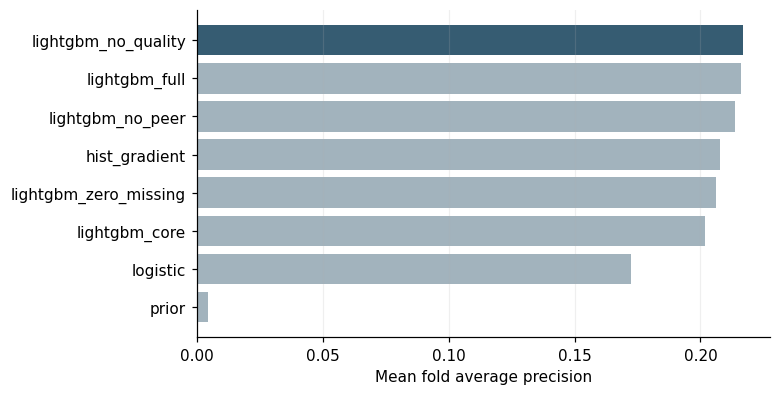

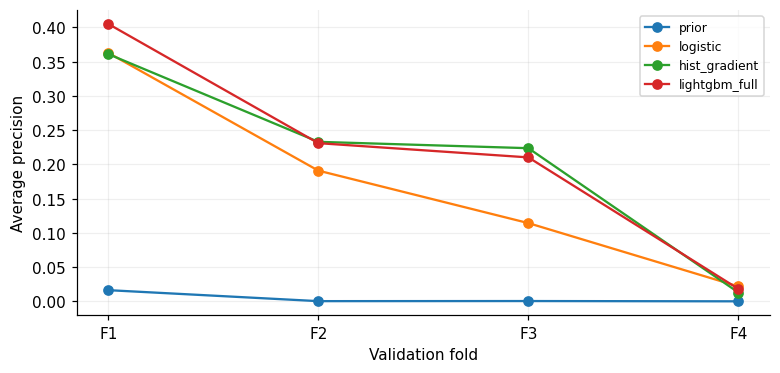

In [6]:
fold_counts=pd.read_csv(EVIDENCE/'fold_counts.csv')
fold_metrics=pd.read_csv(EVIDENCE/'fold_metrics.csv')
comparison=pd.read_csv(EVIDENCE/'model_comparison.csv')
pooled=pd.read_csv(EVIDENCE/'pooled_metrics.csv')
print('Table 1. Chronological fold populations'); display(fold_counts)
print('Table 2. Fold-level average precision'); display(fold_metrics.pivot(index='model',columns='fold',values='ap').round(6))
print('Table 3. Model comparison'); display(comparison.round(6))
print('Table 4. Pooled out-of-fold ranking diagnostics'); display(pooled.round(6))
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(figsize=(7.2,3.7)); ordered=comparison.sort_values('mean_ap'); ax.barh(ordered.model,ordered.mean_ap,color=['#365c72' if n==SELECTED else '#a2b3bd' for n in ordered.model]); ax.set_xlabel('Mean fold average precision'); ax.grid(axis='x',alpha=.2); fig.tight_layout(); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(7.2,3.5)); pivot=fold_metrics.pivot(index='fold',columns='model',values='ap');
for name in ['prior','logistic','hist_gradient','lightgbm_full']:
    ax.plot(pivot.index,pivot[name],marker='o',label=name)
ax.set(ylabel='Average precision',xlabel='Validation fold'); ax.legend(fontsize=8); ax.grid(alpha=.2); fig.tight_layout(); plt.show(); plt.close(fig)

## 7. Feature contribution and capital-zero sensitivity
Compare full LightGBM with fixed feature ablations and an alternative zero treatment under identical model settings. These are development comparisons, not test-informed feature selection. Training-fit importance, if available, is descriptive.

In [7]:
ablation=comparison[comparison.model.str.startswith('lightgbm')].copy()
full=float(ablation.loc[ablation.model.eq('lightgbm_full'),'mean_ap'].iloc[0]); ablation['delta_ap_vs_full']=ablation.mean_ap-full
print('Table 5. Controlled LightGBM specifications'); display(ablation[['model','mean_ap','early_folds_mean_ap','late_fold_ap','delta_ap_vs_full']].round(6))
importance_path=EVIDENCE/'final_model_importance.csv'
if importance_path.is_file():
    print('Selected-model descriptive training-fit importance (top 12)'); display(pd.read_csv(importance_path).head(12))
else:
    print('The selected estimator has no native gain/coefficient diagnostic; use the controlled ablations.')

Table 5. Controlled LightGBM specifications


,model,mean_ap,early_folds_mean_ap,late_fold_ap,delta_ap_vs_full
0,lightgbm_no_quality,0.216778,0.281185,0.023560,0.000641
1,lightgbm_full,0.216137,0.282091,0.018275,0.000000
2,lightgbm_no_peer,0.213555,0.278454,0.018860,-0.002582
4,lightgbm_zero_missing,0.206144,0.266870,0.023965,-0.009993
5,lightgbm_core,0.201882,0.260758,0.025254,-0.014255


Selected-model descriptive training-fit importance (top 12)


,feature,importance,kind
0,ROE_PCT,119764.590853,training_gain
1,ROA_PCT,95251.977613,training_gain
2,TEXAS_LIKE_PCT,94388.451327,training_gain
3,EQUITY_ASSETS_PCT,80343.780407,training_gain
4,RBC1AAJ_REPORTED_PCT,44504.989351,training_gain
5,RBCRWAJ_REPORTED_PCT,22896.737135,training_gain
6,TANGIBLE_EQUITY_ASSETS_PCT,12938.299531,training_gain
7,missingindicator_BROKERED_DEPOSITS_PCT,11462.295055,training_gain
8,ASSET_GROWTH_YOY_PCT,7715.997791,training_gain
9,SECURITIES_ASSETS_PCT,7296.133389,training_gain


## 8. Data-based economic scenarios and locked thresholds
Missed failures are charged once per distinct represented CERT–failure-date. False alarms are charged per negative decision row. The primary missed-event cost uses a median dated FDIC resolution-cost proxy when at least 20 eligible events are available; otherwise the predeclared asset-based scenario is used. These are decision-cost assumptions, not measured supervisory savings.

In [8]:
cost=json.loads((EVIDENCE/'cost_policy.json').read_text())
print('Table 6. Economic proxy provenance'); display(pd.DataFrame([cost]).T.rename(columns={0:'value'}))
sensitivity=pd.read_csv(EVIDENCE/'threshold_sensitivity.csv');
print('Table 7. OOF threshold sensitivity'); display(sensitivity[['model','scenario','c_fp','c_fn','threshold','fp','missed_events','detected_events','event_recall','loss_usd_thousands']].round(6))
print('Table 8. Locked operating policies on OOF scores'); display(pd.read_csv(EVIDENCE/'development_operating.csv').round(6))
print('Frozen thresholds:',S['thresholds'])

Table 6. Economic proxy provenance


,value
c_fn,4422.5
c_fp,60.21
conflicting_dated_cost_events,0
cutoff,2007-12-31
eligible_dated_cost_events,0
excluded_cost_records_by_vintage,1910
fallback_loss_fraction,0.1
median_development_assets,60210.0
median_eligible_fdic_cost,None
median_failed_event_assets,44225.0


Table 7. OOF threshold sensitivity


,model,scenario,c_fp,c_fn,threshold,fp,missed_events,detected_events,event_recall,loss_usd_thousands
0,lightgbm_no_quality,review_half,30.105,4422.50,0.019442,14631,187,968,0.838095,1.267474e+06
1,lightgbm_no_quality,primary,60.210,4422.50,0.033673,9671,239,916,0.793074,1.639268e+06
2,lightgbm_no_quality,review_double,120.420,4422.50,0.074102,4661,347,808,0.699567,2.095885e+06
3,lightgbm_no_quality,miss_half,60.210,2211.25,0.074102,4661,347,808,0.699567,1.047943e+06
4,lightgbm_no_quality,miss_double,60.210,8845.00,0.019442,14631,187,968,0.838095,2.534948e+06
5,prior,review_half,30.105,4422.50,2.000000,0,1155,0,0.000000,5.107988e+06
6,prior,primary,60.210,4422.50,2.000000,0,1155,0,0.000000,5.107988e+06
7,prior,review_double,120.420,4422.50,2.000000,0,1155,0,0.000000,5.107988e+06
8,prior,miss_half,60.210,2211.25,2.000000,0,1155,0,0.000000,2.553994e+06
9,prior,miss_double,60.210,8845.00,2.000000,0,1155,0,0.000000,1.021598e+07


Table 8. Locked operating policies on OOF scores


,model,threshold,tp,fp,fn,tn,alerts,alert_rate,precision,recall,fpr,events,detected_events,missed_events,event_recall,median_lead_days,lead_at_least_90_days,loss_usd_thousands
0,lightgbm_no_quality,0.033673,2665,9671,1388,654654,12336,0.018457,0.216034,0.657538,0.014558,1155,916,239,0.793074,282.5,809,1639268.41
1,prior,2.000000,0,0,4053,664325,0,0.000000,NaN,0.000000,0.000000,1155,0,1155,0.000000,NaN,0,5107987.50


Frozen thresholds: {'lightgbm_no_quality': 0.03367313153323793, 'prior': 2.0}


## 9. Native Spark MLlib demonstration
Fit a Spark pipeline on a sampled training population from the first fold; evaluate all labelled first-fold validation observations at natural prevalence. Sampling is training-only. This demonstration does not participate in model selection.

In [9]:
spark=json.loads((EVIDENCE/'spark_demo.json').read_text())
assert not spark['validation_sampled']
print('Table 9. Spark MLlib development-only diagnostics'); display(pd.DataFrame([spark]).T.rename(columns={0:'value'}))

Table 9. Spark MLlib development-only diagnostics


,value
ap,0.271067
brier,0.019347
features,"[LOG_ASSET, EQUITY_ASSETS_PCT, DEPOSITS_ASSETS..."
fit_seconds,19.759072
log_loss,0.117826
mode,local[2]
positives,3864
prevalence,0.016548
recall_top5pct_by_quarter,0.594462
roc_auc,0.866379


## 10. Sealed development handoff
Confirm that model, features, costs, cutoff and environment are sealed before opening Notebook 07. Save this notebook with its outputs. Do not modify development evidence after sealing.

In [10]:
print('Selected specification:',SELECTED)
print('Final fit:',json.dumps(json.loads((EVIDENCE/'final_fit.json').read_text()),indent=2))
print('Runtime:',json.dumps(DM['environment'],indent=2))
print('Development observations:',S['development_rows'])
print('Development seal:',sha256(EVIDENCE/'development_manifest.json'))
print('Workspace test attempt already exists:',ATTEMPT.exists())
print('Next: Notebook 07 — Historical Test and Evaluation')

Selected specification: lightgbm_no_quality
Final fit: {
  "capital_zero_as_missing": false,
  "features": [
    "LOG_ASSET",
    "EQUITY_ASSETS_PCT",
    "TANGIBLE_EQUITY_ASSETS_PCT",
    "DEPOSITS_ASSETS_PCT",
    "CASH_ASSETS_PCT",
    "SECURITIES_ASSETS_PCT",
    "LOANS_ASSETS_PCT",
    "BROKERED_DEPOSITS_PCT",
    "LOANS_DEPOSITS_PCT",
    "NONCURRENT_LOANS_PCT",
    "ALLOWANCE_LOANS_PCT",
    "TEXAS_LIKE_PCT",
    "ROA_PCT",
    "ROE_PCT",
    "NIM_PCT",
    "RBC1AAJ_REPORTED_PCT",
    "RBCRWAJ_REPORTED_PCT",
    "ASSET_GROWTH_QOQ_PCT",
    "DEPOSIT_GROWTH_QOQ_PCT",
    "ASSET_GROWTH_YOY_PCT",
    "ROA_CHANGE_YOY_PPT",
    "ROA_PEER_DEV_PPT"
  ],
  "first_decision": "1984-06-30",
  "fit_rows": 1082584,
  "fit_seconds": 30.259582093000063,
  "last_decision": "2006-12-31"
}
Runtime: {
  "joblib": "1.5.2",
  "lightgbm": "4.6.0",
  "numpy": "2.2.6",
  "pandas": "2.2.3",
  "pyarrow": "21.0.0",
  "pyspark": "4.0.1",
  "python": "3.13.18",
  "scikit-learn": "1.7.2"
}
Development observa